# ARTI 404 – Image Processing
## Lab 4: Intensity Transformations and Filtering – Spatial Domain
**Assessment Tasks**

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, exposure, io

moon = data.moon()
rocket = data.rocket()
chelsea = data.chelsea()

io.imsave('images/moon.png', moon)
io.imsave('images/rocket.png', rocket)
io.imsave('images/chelsea.png', chelsea)

## Task 1: Contrast stretching (3rd – 80th percentiles)

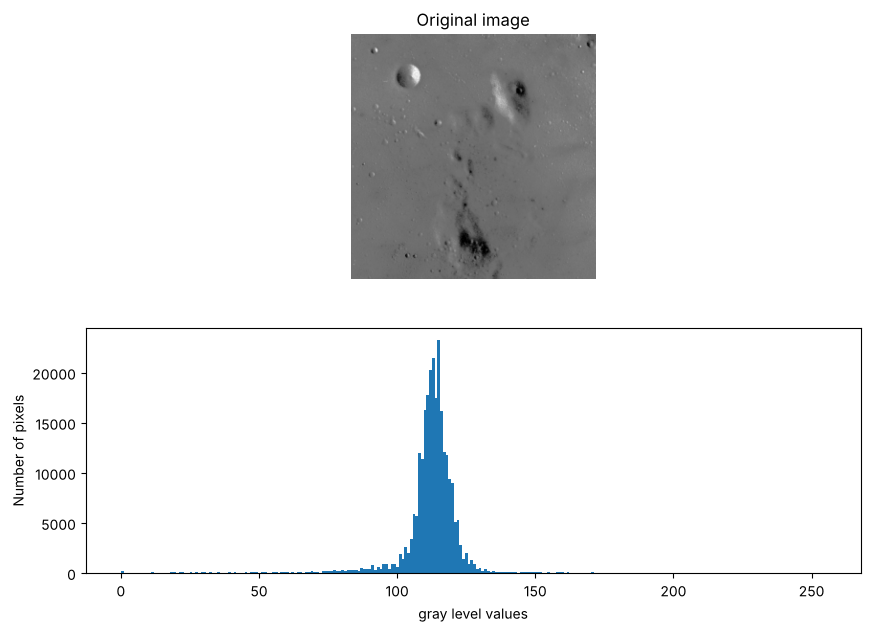

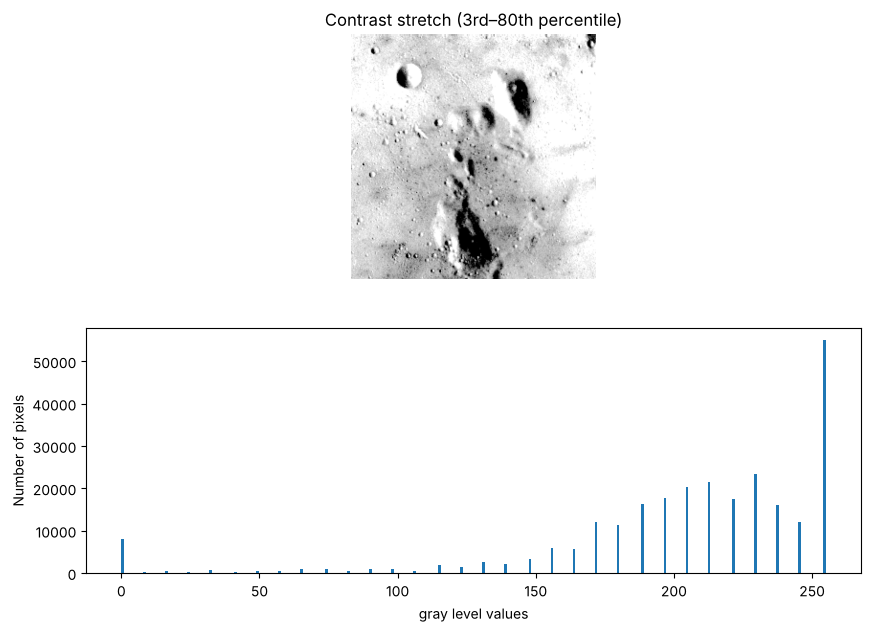

In [2]:
p3, p80 = np.percentile(moon, (3, 80))
moon_rescale = exposure.rescale_intensity(moon, in_range=(p3, p80))

def show_with_hist(image, title, hist_range):
    fig = plt.figure(figsize=(10, 7))
    fig.add_subplot(2, 1, 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(title)
    fig.add_subplot(2, 1, 2)
    plt.hist(image.flat, bins=256, range=hist_range)
    plt.xlabel('gray level values')
    plt.ylabel('Number of pixels')
    plt.show()

show_with_hist(moon, 'Original image', (0, 255))
show_with_hist(moon_rescale, 'Contrast stretch (3rd–80th percentile)', (0, 255))

## Task 2: Histogram equalization

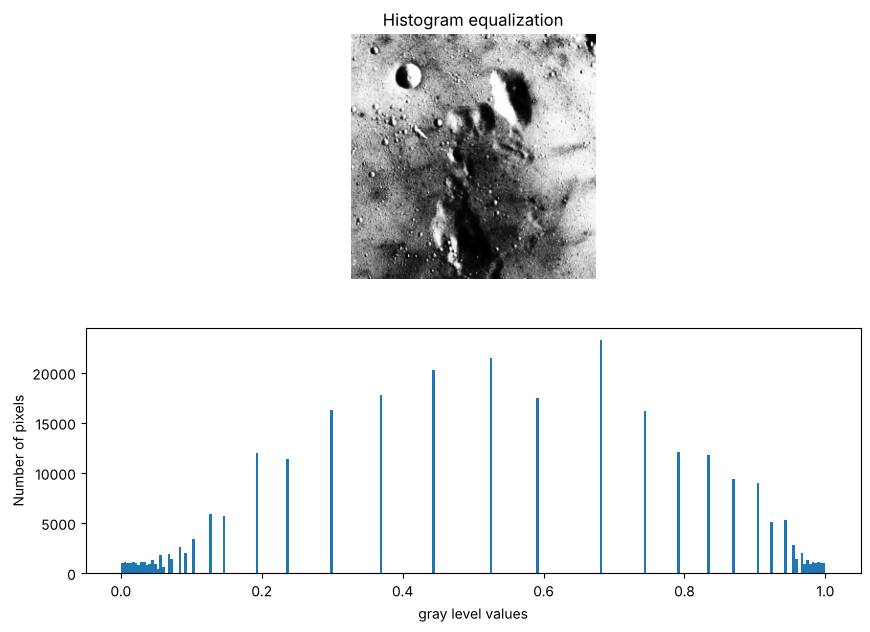

In [3]:
moon_eq = exposure.equalize_hist(moon)
show_with_hist(moon_eq, 'Histogram equalization', (0, 1))

## Task 3: Histogram matching (reference: rocket, image: Chelsea)

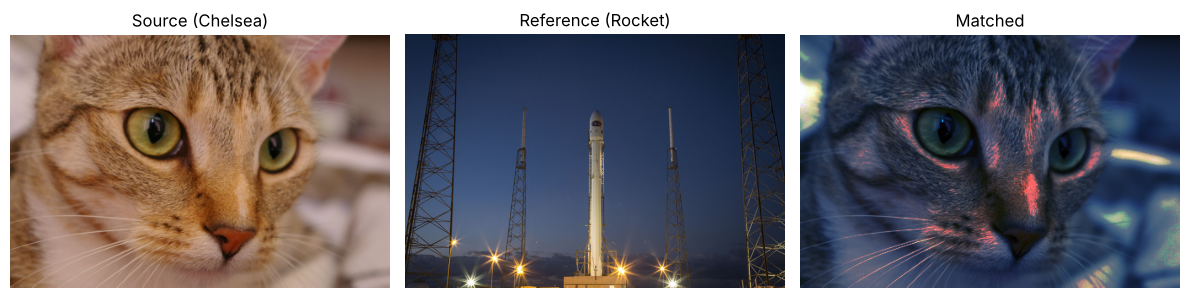

In [4]:
matched = exposure.match_histograms(chelsea, rocket, channel_axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, t in zip(axes, (chelsea, rocket, matched), ('Source (Chelsea)', 'Reference (Rocket)', 'Matched')):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

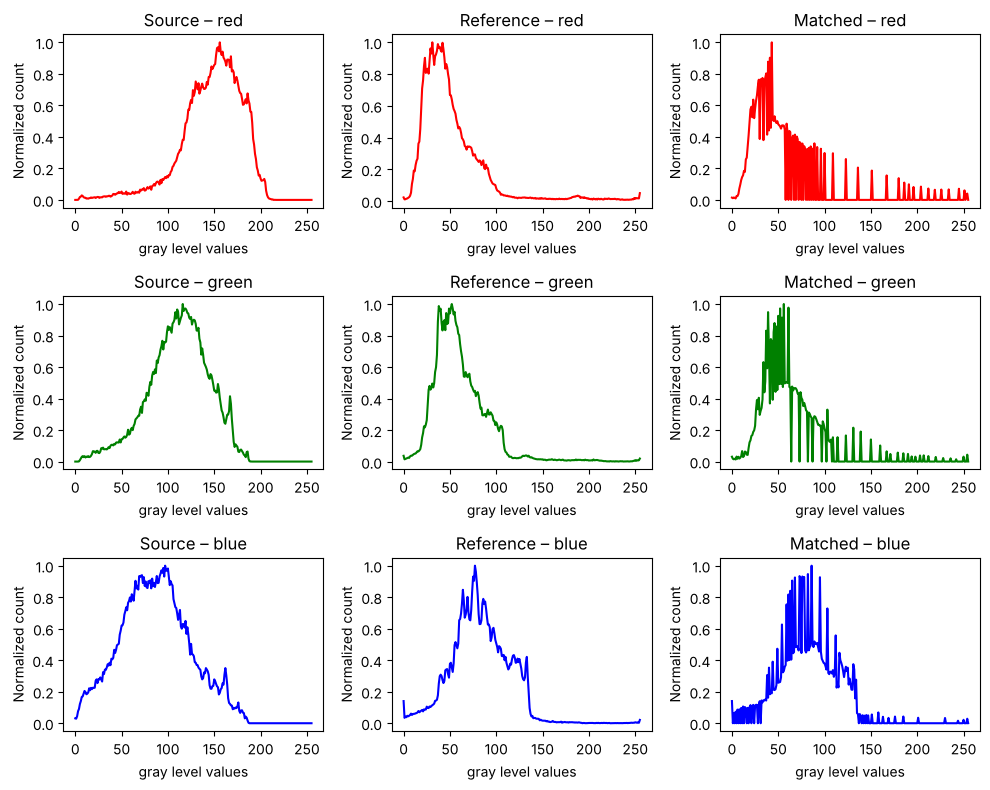

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8))
for col, (im, name) in enumerate(zip((chelsea, rocket, matched), ('Source', 'Reference', 'Matched'))):
    for row, color in enumerate(('red', 'green', 'blue')):
        hist, bins = exposure.histogram(im[..., row], source_range='dtype')
        axes[row, col].plot(bins, hist / hist.max(), color=color)
        axes[row, col].set_title(f'{name} – {color}')
        axes[row, col].set_xlabel('gray level values')
        axes[row, col].set_ylabel('Normalized count')
plt.tight_layout()
plt.show()